# Hälsostudie – Dataanalys

## Introduktion

Syftet med denna analys är att undersöka hälsodata från 800 deltagare. Analyserar  ålder, vikt, längd, blodtryck, kolesterol, rökvanor och förekomst av sjukdom.

Målet är att använda beskrivande statistik, visualisering, simulering och statistiska metoder för att identifiera mönster och dra slutsatser från datasetet.

## 1. Importera bibliotek och skapa reproducerbarhet

Använder Pandas för datahantering, NumPy för beräkningar och simuleringar, Matplotlib/Seaborn för visualisering samt SciPy för statistiska test.


In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
np.random.seed(42)

# Inställningar för tydligare grafer
sns.set_theme(style="whitegrid", font_scale=1.3)
plt.rcParams["figure.figsize"] = (12, 7)

## 2. Läs in och inspektera data



In [79]:
df = pd.read_csv("data/health_study_dataset.csv")

display(df.head())
print("Antal rader och kolumner:", df.shape)
print("\\nDatatyper:")
display(df.dtypes)
print("\\nSaknade värden:")
display(df.isna().sum())
print("\\nAntal duplicerade rader:", df.duplicated().sum())

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


Antal rader och kolumner: (800, 9)
\nDatatyper:


id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object

\nSaknade värden:


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

\nAntal duplicerade rader: 0


### 2.1 Datakvalitet

Kontrollera även kategorier och rimliga värden.

BMI beräknas som vikt i kilogram delat med längd i meter i kvadrat.


In [102]:
# Kontrollera kategorier
print("Kön:", sorted(df["sex"].dropna().unique()))
print("Rökare:", sorted(df["smoker"].dropna().unique()))
print("Sjukdom:", sorted(df["disease"].dropna().unique()))

# Skapa BMI (längd anges i centimeter)
df["height_m"] = df["height"] / 100
df["bmi"] = df["weight"] / (df["height_m"] ** 2)

display(df[["weight", "height", "bmi"]].head())

# Kontrollera numeriska värden
display(df[["age", "height", "weight", "systolic_bp", "cholesterol", "bmi"]].describe())

# Antal orimliga eller ogiltiga värden 
for column in ["age", "height", "weight", "systolic_bp", "cholesterol"]:
    print(f"{column}: {(df[column].dropna() <= 0).sum()} värden <= 0")
print("Sjukdomsvärden utanför 0/1:", (~df["disease"].dropna().isin([0, 1])).sum())


print("""
Tolkning: Datasetet innehåller 800 deltagare och inga duplicerade hela rader enligt kontrollen. 
Kategorierna kodas som F/M, Yes/No och 0/1. BMI är en härledd variabel, inte ett ursprungligt mätvärde. 
""")

Kön: ['F', 'M']
Rökare: ['No', 'Yes']
Sjukdom: [np.int64(0), np.int64(1)]


,weight,height,bmi
0,65.8,168.9,23.065698
1,95.9,180.4,29.467653
2,82.2,169.9,28.476398
3,93.1,157.7,37.435729
4,104.1,192.6,28.063263


,age,height,weight,systolic_bp,cholesterol,bmi
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,171.849250,73.413000,149.178625,4.929150,24.933722
std,14.501118,9.804259,13.685059,12.793360,0.848413,4.661261
min,18.000000,144.400000,33.700000,106.800000,2.500000,12.634903
25%,39.000000,164.775000,64.800000,140.900000,4.327500,21.918637
50%,50.000000,171.350000,73.200000,149.400000,4.970000,24.703622
75%,59.000000,178.925000,82.600000,157.600000,5.482500,28.011842
max,90.000000,200.400000,114.400000,185.900000,7.880000,40.141267


age: 0 värden <= 0
height: 0 värden <= 0
weight: 0 värden <= 0
systolic_bp: 0 värden <= 0
cholesterol: 0 värden <= 0
Sjukdomsvärden utanför 0/1: 0

Tolkning: Datasetet innehåller 800 deltagare och inga duplicerade hela rader enligt kontrollen. 
Kategorierna kodas som F/M, Yes/No och 0/1. BMI är en härledd variabel, inte ett ursprungligt mätvärde. 



## 3. Beskrivande statistik

Den beskrivande statistiken visar typiska värden och variation. Medelvärde och median kan jämföras för att upptäcka skevhet, men inga orsakssamband kan dras. Därefter undersöker vi fördelningarna visuellt.

In [81]:
# Select relevant numerical columns

numeric_columns = [
    "age",
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]

# Calculate descriptive statistics
mean = df[numeric_columns].mean()
median = df[numeric_columns].median()
min = df[numeric_columns].min()
max = df[numeric_columns].max()
std = df[numeric_columns].std()
count = df[numeric_columns].count()


statistics = pd.DataFrame({
    "Mean": mean,
    "Median": median,
    "Min": min,
    "Max": max,
    "Standardavvikelse": std,
    "Antal": count
})

statistics.round(2)


,Mean,Median,Min,Max,Standardavvikelse,Antal
age,49.43,50.00,18.0,90.00,14.50,800
height,171.85,171.35,144.4,200.40,9.80,800
weight,73.41,73.20,33.7,114.40,13.69,800
systolic_bp,149.18,149.40,106.8,185.90,12.79,800
cholesterol,4.93,4.97,2.5,7.88,0.85,800


## 4. Exploratory Data Analysis (EDA) – visualiseringar

Syfte: EDA används för att hitta mönster, möjliga avvikare och samband som kan motivera en tydligt formulerad hypotes. Ett samband i en figur är inte bevis för orsak och verkan

Graferna visar  fördelningar och möjliga skillnader mellan grupper.


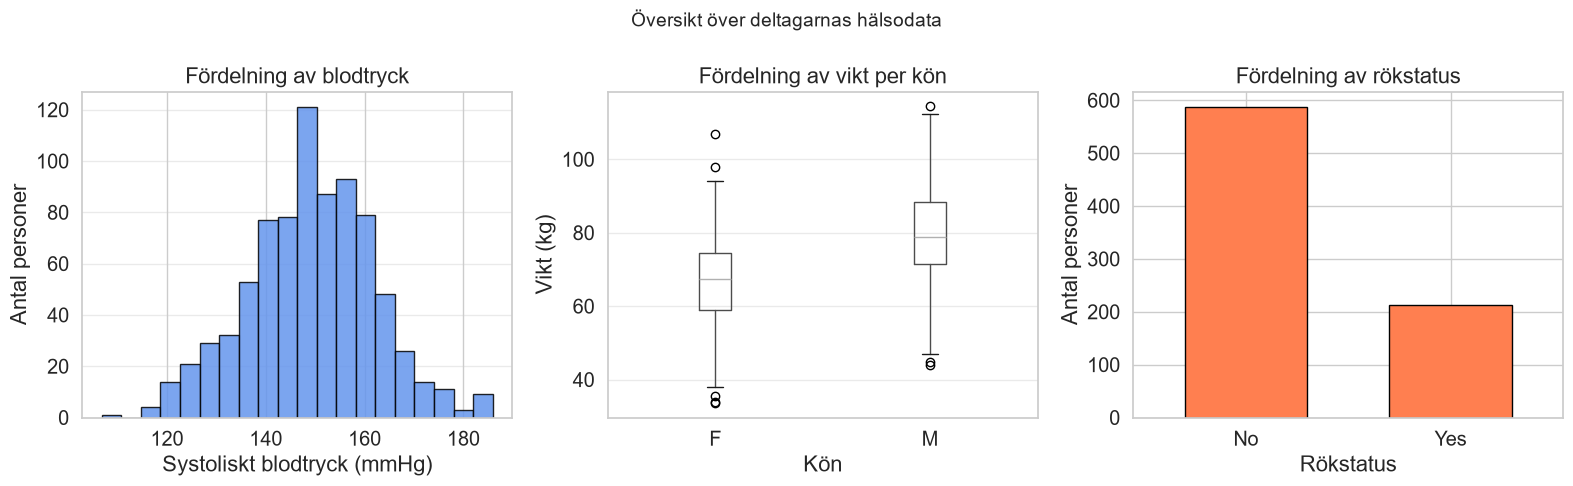

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16,5))

#---------------------------------------
#  Histogram - blodtryck
#---------------------------------------

axes[0].hist(df["systolic_bp"], bins= 20, color="cornflowerblue", edgecolor="black", alpha=0.85)
axes[0].set(title="Fördelning av blodtryck", xlabel= "Systoliskt blodtryck (mmHg)", ylabel="Antal personer" )
axes[0].grid(axis="y", alpha=0.4)


#---------------------------------------
# Vikt per kön 
#---------------------------------------


df.boxplot(
    column="weight",
    by="sex",
    ax=axes[1],
    grid=False
)

axes[1].set_title("Fördelning av vikt per kön")
axes[1].set_xlabel("Kön")
axes[1].set_ylabel("Vikt (kg)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.4)

#---------------------------------------
# Rökstatus
#---------------------------------------

df["smoker"].value_counts().plot(kind="bar", ax=axes[2],  color="coral", edgecolor="black",  width=0.6)
axes[2].set_title("Fördelning av rökstatus")
axes[2].set_xlabel("Rökstatus")
axes[2].set_ylabel("Antal personer")
axes[2].tick_params(axis="x", rotation=0)

fig.suptitle("Översikt över deltagarnas hälsodata", fontsize=14)
plt.tight_layout()
plt.show()






Tolkning – EDA: Histogram och boxplottar beskriver spridning och möjliga avvikare. Korrelation är inte kausalitet. Jämförelser mellan sjukdomsgrupper och rökgrupper är beskrivande här och kan påverkas av bland annat ålder.

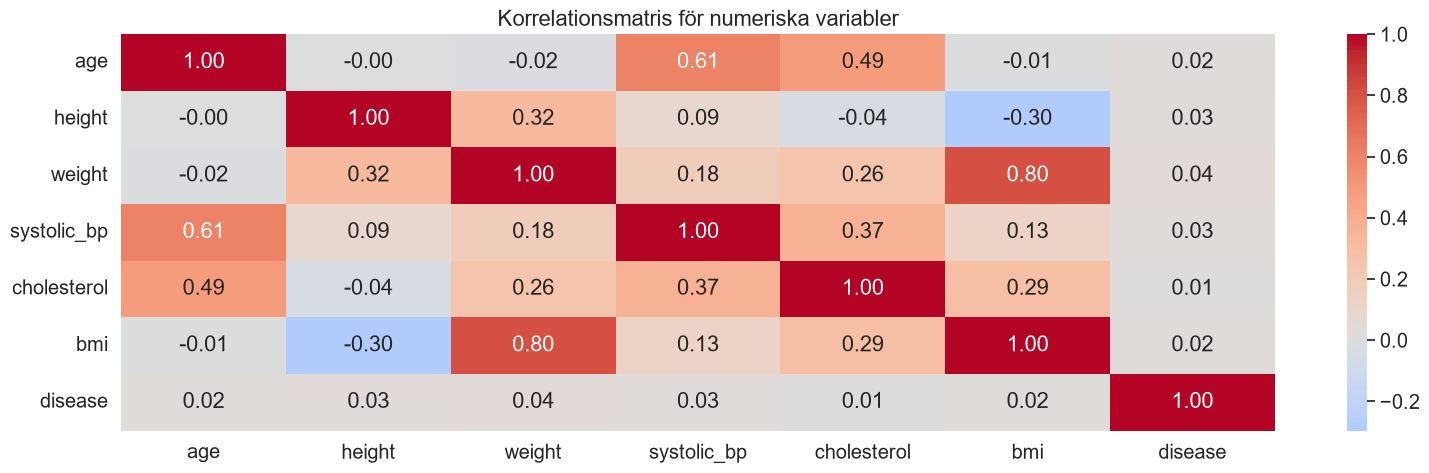

In [83]:
# Korrelationsheatmap för numeriska variabler

corr_columns = ["age", "height", "weight", "systolic_bp", "cholesterol", "bmi", "disease"]
correlation_matrix = df[corr_columns].corr(numeric_only=True)

plt.figure(figsize=(16, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Korrelationsmatris för numeriska variabler")
plt.tight_layout()
plt.show()


Korrelation är inte kausalitet. 

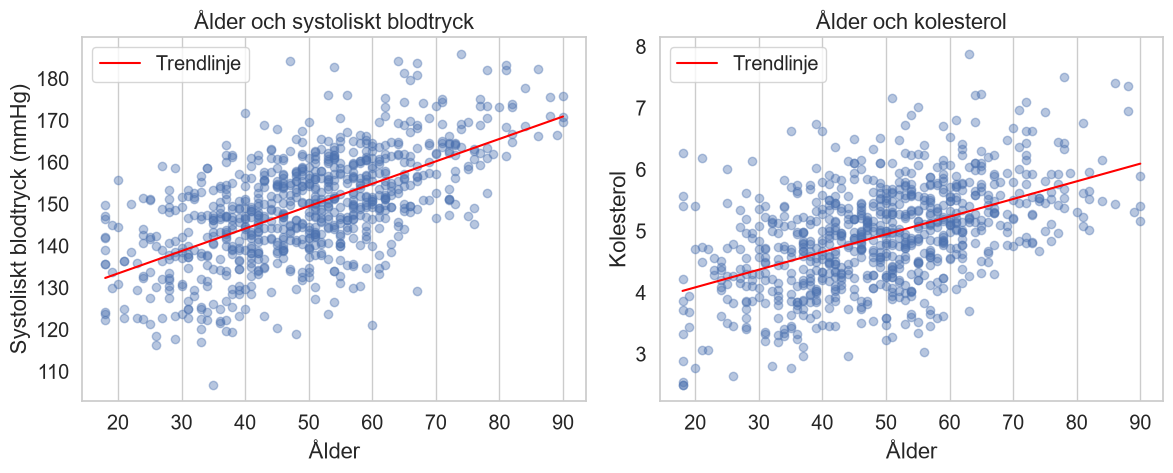

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Ålder och systoliskt blodtryck
axes[0].scatter(df["age"], df["systolic_bp"], alpha=0.4)

# Calculate trendline
slope, intercept = np.polyfit(df["age"], df["systolic_bp"], 1)
x_line = np.linspace(df["age"].min(), df["age"].max(), 100)
y_line = slope * x_line + intercept

axes[0].plot(x_line, y_line, color="red", label="Trendlinje")

axes[0].set(title="Ålder och systoliskt blodtryck", xlabel="Ålder", ylabel="Systoliskt blodtryck (mmHg)")
axes[0].grid(axis="y")
axes[0].legend()


#  Ålder och kolesterol
axes[1].scatter(df["age"], df["cholesterol"], alpha=0.4)

# Calculate trendline
slope, intercept = np.polyfit(df["age"], df["cholesterol"], 1)
x_line = np.linspace(df["age"].min(), df["age"].max(), 100)
y_line = slope * x_line + intercept

axes[1].plot(x_line, y_line, color="red", label="Trendlinje")

axes[1].set(title="Ålder och kolesterol", xlabel="Ålder", ylabel="Kolesterol")
axes[1].grid(axis="y")
axes[1].legend()

plt.tight_layout()
plt.show()

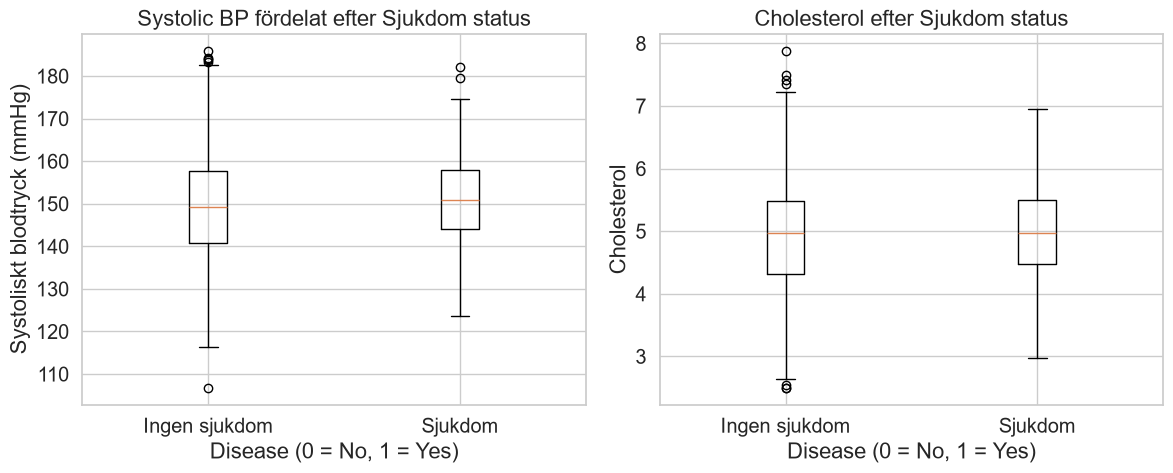

In [85]:
blodtryck_sjukdom = df.groupby("disease")["systolic_bp"]
cholestrol_sjukdom = df.groupby("disease")["cholesterol"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


data = [
    blodtryck_sjukdom.get_group(0),
    blodtryck_sjukdom.get_group(1)
]
axes[0].boxplot(
    data,
    tick_labels=["Ingen sjukdom", "Sjukdom"]
)

axes[0].set_title("Systolic BP fördelat efter Sjukdom status")
axes[0].set_xlabel("Disease (0 = No, 1 = Yes)")
axes[0].set_ylabel("Systoliskt blodtryck (mmHg)")


data = [
    cholestrol_sjukdom.get_group(0),
    cholestrol_sjukdom.get_group(1)
]
axes[1].boxplot(
    data,
    tick_labels=["Ingen sjukdom", "Sjukdom"]
)

axes[1].set_title("Cholesterol efter Sjukdom status")
axes[1].set_xlabel("Disease (0 = No, 1 = Yes)")
axes[1].set_ylabel("Cholesterol")

plt.tight_layout()
plt.show()

### 4.1 Rökning och sjukdom – antal och andel

Korstabellen visar både antal och andel inom varje rökgrupp. `normalize="index"` betyder att procenten räknas inom respektive rad (rökstatus), vilket gör grupperna jämförbara.


In [86]:
# Antal personer
antal = pd.crosstab(df["smoker"], df["disease"])

# Andel i procent inom varje rökgrupp
andel = pd.crosstab(
    df["smoker"],
    df["disease"],
    normalize="index"
) * 100


smoking_disease_table = pd.concat(
    {"Antal": antal, "Andel (%)": andel},
    axis=1
)

display(smoking_disease_table.round(1))

Antal     Andel (%)     
disease     0   1         0    1
smoker                          
No        559  28      95.2  4.8
Yes       194  19      91.1  8.9

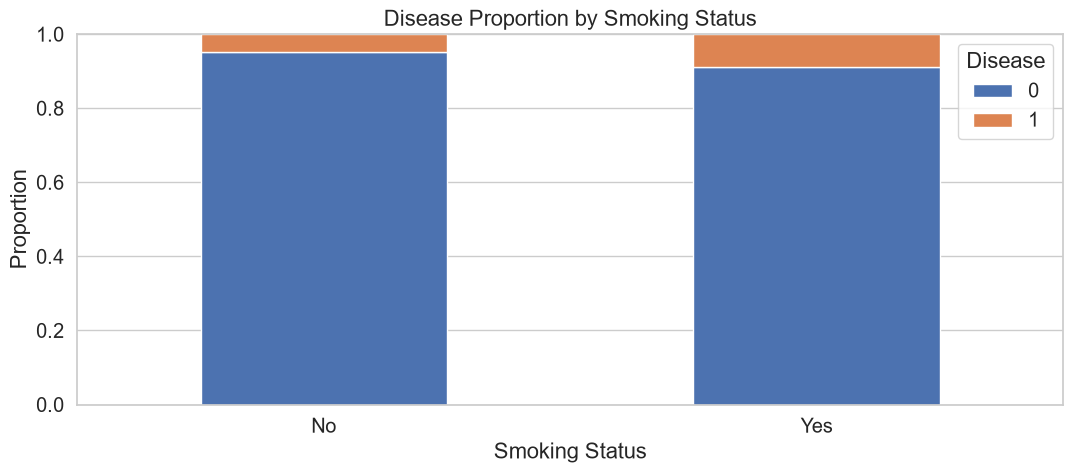

In [87]:
# Calculate proportions
smoking_disease = pd.crosstab(
    df["smoker"],
    df["disease"],
    normalize="index"
)


# Plot
ax = smoking_disease.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

ax.set_title("Disease Proportion by Smoking Status")
ax.set_xlabel("Smoking Status")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
ax.legend(title="Disease")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Simulering – sjukdomsförekomst

Först beräknas den observerade andelen med sjukdomen. Därefter simuleras 1 000 oberoende personer med samma sannolikhet för sjukdom som i datasetet.

Simuleringen visar hur mycket andelen kan variera i ett slumpmässigt stickprov av 1 000 personer.

Här använder den observerade sjukdomsandelen som sannolikhet i en binomialmodell.

Verklig sjukdomsandel: 5.88%
Simulerad sjukdomsandel: 5.60%
Skillnad: 0.27%


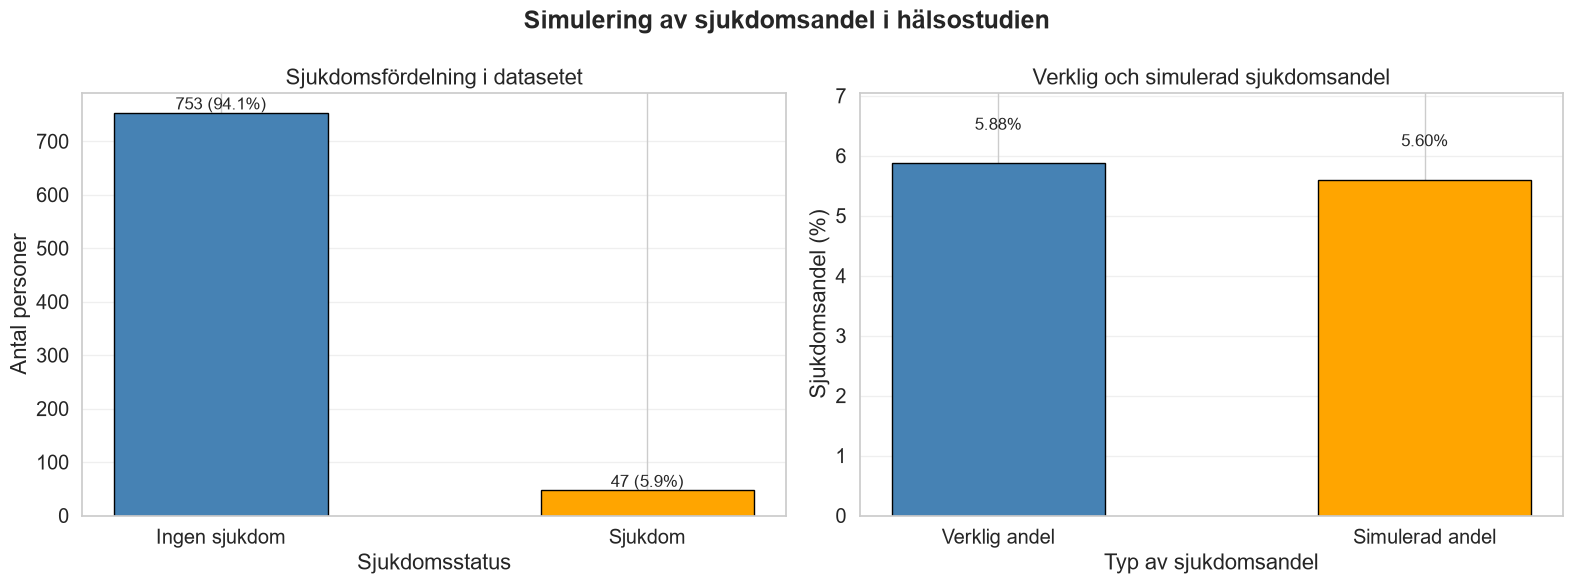

In [88]:

# ---------------------------------------
# 1. Beräkna sjukdomsfördelningen i datasetet
# ---------------------------------------

disease_counts = df["disease"].value_counts().sort_index()

disease_percentages = (
    df["disease"].value_counts(normalize=True).sort_index() * 100
)


# ---------------------------------------
# 2. Simulering av 1000 personer
# ---------------------------------------

# Beräkna den verkliga sjukdomsandelen
disease_percent = df["disease"].mean()

np.random.seed(42)

# Simulera 1000 personer med samma sjukdomssannolikhet
simulation = np.random.binomial(
    n=1,
    p=disease_percent,
    size=1000
)

# Beräkna den simulerade sjukdomsandelen
simulated_percentage = simulation.mean()

# Beräkna skillnaden mellan verklig och simulerad andel
difference = abs(disease_percent - simulated_percentage)

# Skriv ut resultaten
print(f"Verklig sjukdomsandel: {disease_percent:.2%}")
print(f"Simulerad sjukdomsandel: {simulated_percentage:.2%}")
print(f"Skillnad: {difference:.2%}")


# ---------------------------------------
# Visualisering av sjukdomsfördelning och simulering
# ---------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


# Sjukdomsfördelning i datasetet

bars = axes[0].bar(
    ["Ingen sjukdom", "Sjukdom"],
    disease_counts.values,
    color=["steelblue", "orange"],
    edgecolor="black",
    width=0.5
)

# Visa antal och procent ovanför staplarna
for i, bar in enumerate(bars):
    height = bar.get_height()

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)} ({disease_percentages.iloc[i]:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=12
    )

axes[0].set_title("Sjukdomsfördelning i datasetet")
axes[0].set_xlabel("Sjukdomsstatus")
axes[0].set_ylabel("Antal personer")
axes[0].grid(axis="y", alpha=0.3)


#  Jämförelse av sjukdomsandelar

labels = ["Verklig andel", "Simulerad andel"]

values = [
    disease_percent * 100,
    simulated_percentage * 100
]

bars = axes[1].bar(
    labels,
    values,
    color=["steelblue", "orange"],
    edgecolor="black",
    width=0.5
)

# Visa procentvärden ovanför staplarna
for bar in bars:
    height = bar.get_height()

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12
    )

axes[1].set_title("Verklig och simulerad sjukdomsandel")
axes[1].set_xlabel("Typ av sjukdomsandel")
axes[1].set_ylabel("Sjukdomsandel (%)")
axes[1].set_ylim(0, np.max(values) * 1.2)
axes[1].grid(axis="y", alpha=0.3)


# Gemensam titel och layout
fig.suptitle(
    "Simulering av sjukdomsandel i hälsostudien",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


Tolkning – simulering
Den observerade sjukdomsandelen är 5,88 %, och den simulerade andelen bland 1 000 personer är 5,60 %. Skillnaden är cirka 0,28 procentenheter. Den lilla skillnaden illustrerar slumpvariation. Simuleringen använder den observerade andelen som modellparameter och kan därför inte själv validera den.

## 6. Konfidensintervall för medelvärdet av systoliskt blodtryck

Ett 95-procentigt konfidensintervall beskriver en metods osäkerhet vid skattning av populationsmedelvärdet. I upprepade stickprov skulle cirka 95 % av intervallen täcka det sanna medelvärdet, om metodens antaganden är uppfyllda.

Vi jämför:
1. **Normal approximation:** 
2. **Bootstrap:** 

Metodval: Skattar  först medelblodtrycket med normalapproximation och jämför sedan med ett bootstrapintervall. Båda använder samma ursprungliga observationer och är inte två oberoende studier.


In [89]:
def ci_mean_normal(data):

    # Omvandla data till en NumPy-array
    data = np.asarray(data, dtype=float)

    # Ta bort saknade värden
    data = data[~np.isnan(data)]

    # Beräkna stickprovsstorlek och statistik
    n = len(data)
    mean = np.mean(data)
    s = np.std(data, ddof=1)

    # Beräkna standardfel
    SE = s / np.sqrt(n)

    # Kritisk Z-nivå för 95 % konfidensintervall
    z_critical = stats.norm.ppf(0.975)

    # Beräkna felmarginal
    half_width = z_critical * SE

    # Beräkna konfidensintervallet
    lower = mean - half_width
    upper = mean + half_width

    return lower, upper, mean, s, SE, n



def mean_bootstrap(data, B=10000, seed=42):

    # Omvandla data till en NumPy-array
    data = np.asarray(data, dtype=float)

    # Ta bort saknade värden
    data = data[~np.isnan(data)]

    # Antal observationer
    n = len(data)

    # Skapa slumpgenerator
    rng = np.random.default_rng(seed)

    # Lagra bootstrap-medelvärden
    boot_means = np.empty(B)

    # Skapa bootstrap-stickprov
    for b in range(B):

        boot_sample = rng.choice(
            data,
            size=n,
            replace=True
        )

        boot_means[b] = np.mean(boot_sample)

    return boot_means

# Använd systoliskt blodtryck
bp = df["systolic_bp"] . to_numpy()
lower, upper, mean, s, SE, n = ci_mean_normal(bp)


# Genomför bootstrap-simulering
boot_means = mean_bootstrap(bp)

# Beräkna bootstrap-konfidensintervall
ci_boot_lower, ci_boot_upper = np.percentile(boot_means, [2.5, 97.5])

-------------------Normalapproximation Methoden---------------------------

Antal observationer                 : 800
Medelvärde för systoliskt blodtryck : 149.18
Stickprovsstandardavvikelse         : 12.79
Standardfel                         : 0.45
95 % Z-konfidensintervall           : (148.29, 150.07)

--------------------------Bootstrap Methoden-------------------------------

Bootstrap-medelvärde                : 149.19
Bootstrap-standardfel               : 0.45
95 % Bootstrap-konfidensintervall   : (148.31, 150.05)



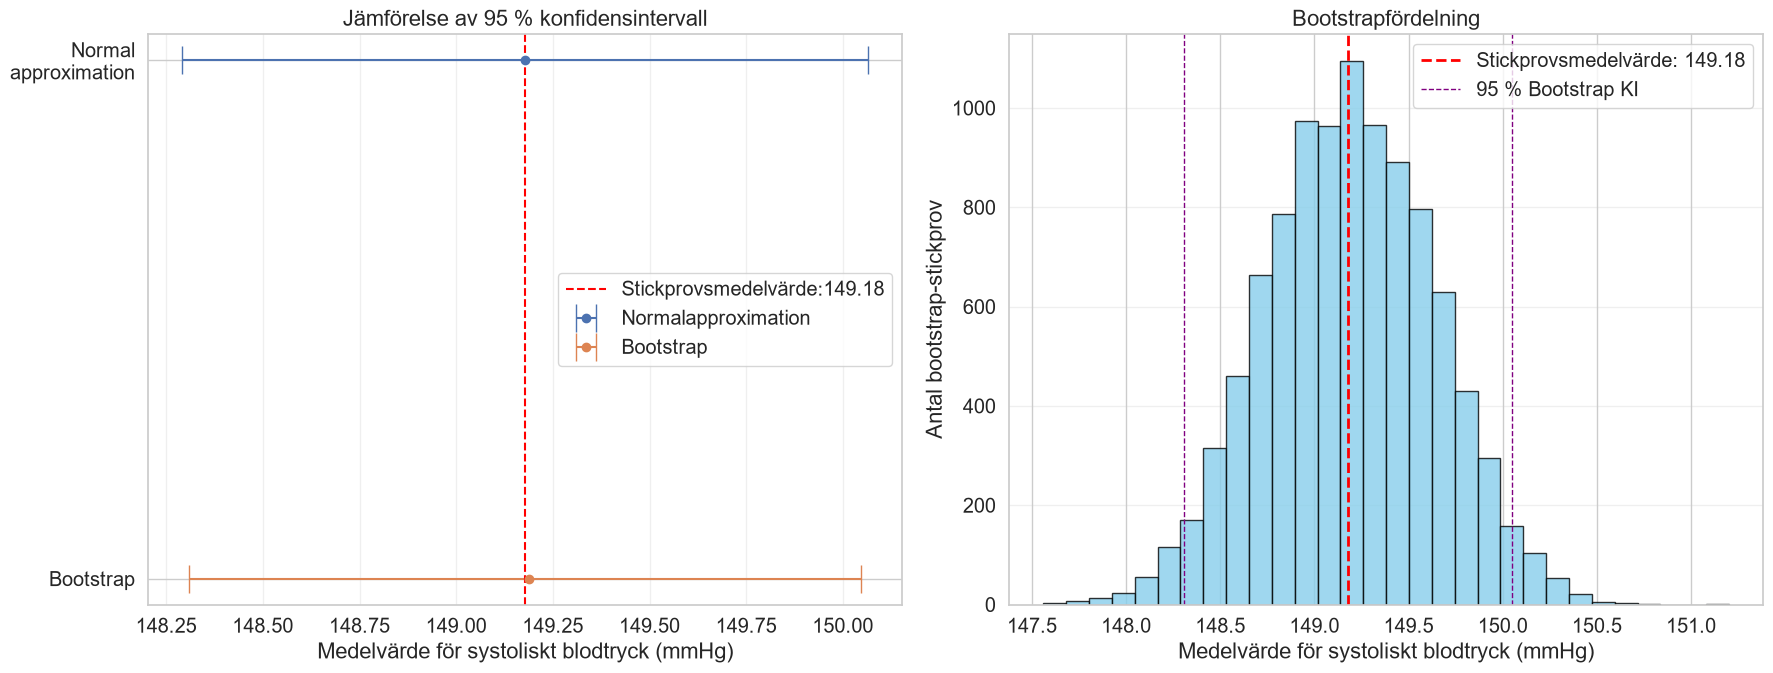

In [90]:


print("-------------------Normalapproximation Methoden---------------------------\n")
print(f"Antal observationer                 : {n}")
print(f"Medelvärde för systoliskt blodtryck : {mean:.2f}")
print(f"Stickprovsstandardavvikelse         : {s:.2f}")
print(f"Standardfel                         : {SE:.2f}")  
print(f"95 % Z-konfidensintervall           : ({lower:.2f}, {upper:.2f})")

print ("\n--------------------------Bootstrap Methoden-------------------------------\n")
print(f"Bootstrap-medelvärde                : {np.mean(boot_means):.2f}")
print(f"Bootstrap-standardfel               : {np.std(boot_means, ddof=1):.2f}")
print(f"95 % Bootstrap-konfidensintervall   : ({ci_boot_lower:.2f}, {ci_boot_upper:.2f})\n")


#---------------------------------------------------
# Visualesering  Confidence interval 
#-----------------------------------------

# Jamföre Normal Aproximation and bootstrap konfidence interval 

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].errorbar(
    mean,
    1,
    xerr=[[mean - lower], [upper - mean]],
    fmt="o",
    capsize=10,
    label="Normalapproximation"
)

axes[0].errorbar(
    np.mean(boot_means),
    0,
    xerr=[[
        np.mean(boot_means) - ci_boot_lower
    ], [
        ci_boot_upper - np.mean(boot_means)
    ]],
    fmt="o",
    capsize=10,
    label="Bootstrap"
)

axes[0].axvline(
    mean,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Stickprovsmedelvärde:{mean:.2f}"
)

axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Bootstrap", "Normal\napproximation"])
axes[0].set_xlabel("Medelvärde för systoliskt blodtryck (mmHg)")
axes[0].set_title("Jämförelse av 95 % konfidensintervall")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.3)



# Visualering av  Bootstrap Fördelning


axes[1].hist(
    boot_means,
    bins=30,
    color="skyblue",
    edgecolor="black",
    alpha=0.8
)

axes[1].axvline(
    mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Stickprovsmedelvärde: {mean:.2f}"
)

axes[1].axvline(
    ci_boot_lower,
    color="purple",
    linestyle="--",
    linewidth= 1,
    label="95 % Bootstrap KI"
)

axes[1].axvline(
    ci_boot_upper,
    color="purple",
    linewidth= 1,
    linestyle="--"
)

axes[1].set_xlabel("Medelvärde för systoliskt blodtryck (mmHg)")
axes[1].set_ylabel("Antal bootstrap-stickprov")
axes[1].set_title("Bootstrapfördelning")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Tolkning – konfidensintervall
Medelvärdet för systoliskt blodtryck är 149,18 mmHg (n = 800). Normalapproximationens 95 %-intervall är 148,29–150,07 mmHg. Bootstrapintervallet kan jämföras med detta i figuren: liknande intervall talar för att metoderna ger samstämmiga skattningar i detta stickprov. Ett 95 %-konfidensintervall betyder inte att det finns 95 % sannolikhet att det fasta populationsmedelvärdet ligger i just detta beräknade intervall.

## 7. Hypotesprövning – rökare och blodtryck

**Fråga:** Har rökare högre genomsnittligt systoliskt blodtryck än icke-rökare?

Vi använder ett ensidigt Welch t-test för två oberoende grupper.

- H0: μ_rökare ≤ μ_icke-rökare
- H1: μ_rökare > μ_icke-rökare

Signifikansnivå: α = 0,05.

**Metodval**: Welch-testet jämför två oberoende gruppers medelvärden utan att anta lika varians. Testet är ensidigt eftersom den fördefinierade frågan gäller högre blodtryck hos rökare. Ett tvåsidigt 95 %-intervall redovisas separat för att visa rimliga skillnader i båda riktningar.


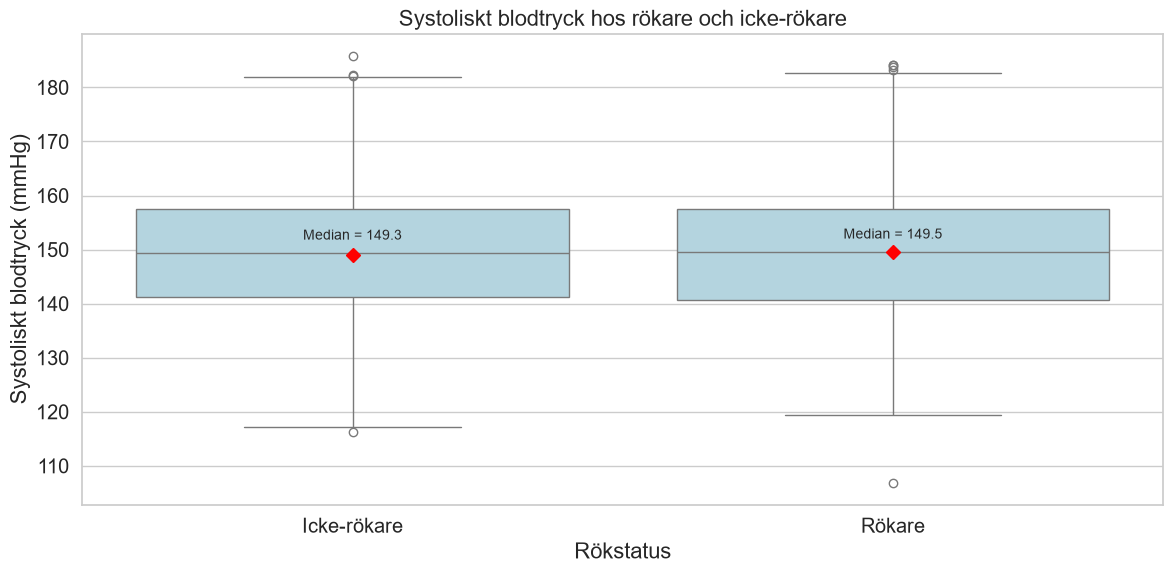

In [ ]:
# Dela upp blodtrycket i två grupper
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()
smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()

# Beräkna medianvärden och antal personer
groups = [non_smokers, smokers]
medians = [group.median() for group in groups]
counts = [len(group) for group in groups]

# Skapa boxplot
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df,
    x="smoker",
    y="systolic_bp",
    order=["No", "Yes"],
    color="lightblue",
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": 7
    }
)

# Visa medianvärdet ovanför varje box
for i, median in enumerate(medians):
    ax.text(
        i,
        median + 2,
        f"Median = {median:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xticks([0, 1], ["Icke-rökare", "Rökare"])
plt.xlabel("Rökstatus")
plt.ylabel("Systoliskt blodtryck (mmHg)")
plt.title("Systoliskt blodtryck hos rökare och icke-rökare")

plt.tight_layout()
plt.show()

Den ensidiga nedre gränsen motsvarar riktningen i testet (rökare > icke-rökare). Det tvåsidiga 95 %-intervallet behålls eftersom det tydligt visar osäkerhet åt båda hållen. Cohen’s d beskriver skillnaden i standardavvikelseenheter; den faktiska skillnaden i mmHg är viktig för praktisk betydelse. Ett icke-signifikant resultat bevisar inte att grupperna är identiska.

-------Rökare-------
Antal                                       : 213
Medelvärde                                  : 149.52 mmHg

\n--------Icke-rökare---------
Antal                                       : 587
Medelvärde                                  : 149.05 mmHg

\n---------Jämförelse----------
Skillnad mean mellan rökare och icke-rökare : 0.47 mmHg
t-statistik                                 : 0.4503
p-värde (ensidigt)                          : 0.3264

------- 95 % konfidensintervall -------
Nedre gräns           : -1.59 mmHg
Övre gräns            : 2.53 mmHg

Ensidig 95 % nedre konfidensgräns: [-1.26, +∞) mmHg

Cohen's d: 0.037

Beslut: Förkasta inte H0. Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.


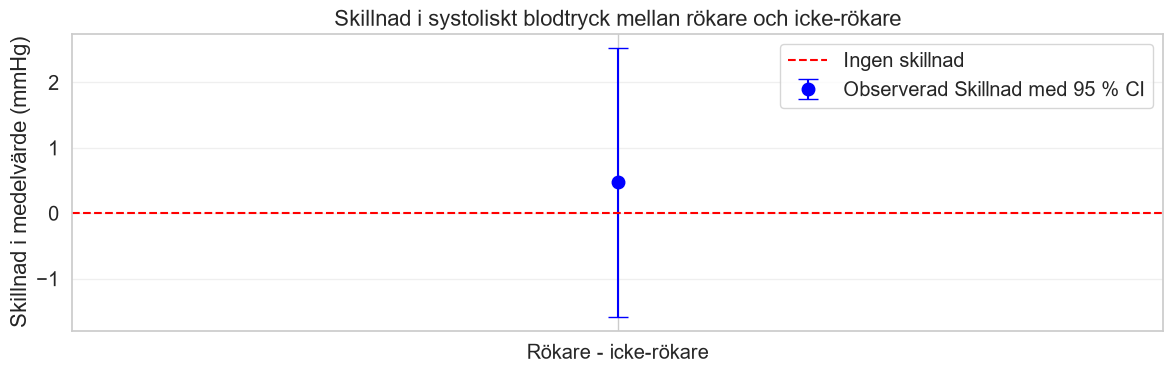

In [100]:

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

# Beräkna medelvärden
mean_smokers = smokers.mean()
mean_non_smokers = non_smokers.mean()

# Observerad skillnad
observed_skillnad = mean_smokers - mean_non_smokers

# Welch's t-test (ensidigt)
test_result = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

# ----------------------------------
# 95 % konfidensintervall med Statsmodels
# ----------------------------------

smoker_stats = DescrStatsW(smokers)
non_smoker_stats = DescrStatsW(non_smokers)

comparison = CompareMeans(smoker_stats, non_smoker_stats)

ci_lower, ci_upper = comparison.tconfint_diff(
    alpha=0.05,
    usevar="unequal"

)


# ensidig nedre 95 % konfidensgräns
ci_one_lower, ci_one_upper = comparison.tconfint_diff(
    alpha=0.05, usevar="unequal", alternative="larger"
)


# Cohen's d – standardiserad skillnad i medelvärde
n1, n2 = len(smokers), len(non_smokers)
s1, s2 = smokers.std(ddof=1), non_smokers.std(ddof=1)
pooled_sd = np.sqrt(((n1 - 1)*s1**2 + (n2 - 1)*s2**2) / (n1+n2-2))
cohens_d = observed_skillnad / pooled_sd

print("-------Rökare-------")
print(f"Antal                                       : {len(smokers)}")
print(f"Medelvärde                                  : {mean_smokers:.2f} mmHg\n")

print("\\n--------Icke-rökare---------")
print(f"Antal                                       : {len(non_smokers)}")
print(f"Medelvärde                                  : {mean_non_smokers:.2f} mmHg\n")

print("\\n---------Jämförelse----------")
print(f"Skillnad mean mellan rökare och icke-rökare : {observed_skillnad:.2f} mmHg")
print(f"t-statistik                                 : {test_result.statistic:.4f}")
print(f"p-värde (ensidigt)                          : {test_result.pvalue:.4f}")

print("\n------- 95 % konfidensintervall -------")
print(f"Nedre gräns           : {ci_lower:.2f} mmHg")
print(f"Övre gräns            : {ci_upper:.2f} mmHg")
print(f"\nEnsidig 95 % nedre konfidensgräns: [{ci_one_lower:.2f}, +∞) mmHg")
print(f"\nCohen's d: {cohens_d:.3f}")

if test_result.pvalue < 0.05:
    print("\nBeslut: Förkasta H0. Resultatet ger statistiskt stöd för högre medelblodtryck bland rökare.")
else:
    print("\nBeslut: Förkasta inte H0. Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.")


# ----------------------------------
# Visualisering av skillnaden
# ----------------------------------

plt.figure(figsize=(12, 4))

plt.errorbar(
    0,
    observed_skillnad,
    yerr=[[observed_skillnad - ci_lower],
          [ci_upper - observed_skillnad]],
    fmt="o",
    color="blue",
    markersize=9,
    capsize=7,
    label="Observerad Skillnad med 95 % CI"
)

# Referenslinje vid noll
plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Ingen skillnad"
)

plt.xticks([0], ["Rökare - icke-rökare"])
plt.ylabel("Skillnad i medelvärde (mmHg)")
plt.title("Skillnad i systoliskt blodtryck mellan rökare och icke-rökare")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Tolkning – hypotesprövning
Rökare har i stickprovet medelblodtryck 149,52 mmHg (n = 213) och icke-rökare 149,05 mmHg (n = 587). Den observerade skillnaden är +0,47 mmHg. Den är liten i förhållande till variationen, och det ensidiga Welch-testet ger inte tillräckligt stöd för att rökare har högre populationsmedelblodtryck vid α = 0,05. Detta bevisar inte att gruppernas sanna medelvärden är lika. Det tvåsidiga 95 %-intervallet för skillnaden beskriver osäkerheten och kan inkludera både negativa och positiva värden. Eftersom analysen är observationell kan den inte fastställa orsakssamband.

## 8. Poweranalys

Power är sannolikheten att ett test förkastar nollhypotesen när en viss alternativhypotes faktiskt är sann.


Simuleringen antar ungefär normalfördelade blodtryck inom grupperna, använder observerade gruppstorlekar och gruppstandardavvikelser. Vi gör många Welch-test och räknar andelen p-värden under 0,05.

Vi undersöker hur ofta samma test skulle upptäcka olika antagna skillnader med samma gruppstorlekar och ungefär samma spridning. Power beräknad från den observerade effekten är inte ett mått på sannolikheten att nollhypotesen är sann.

In [93]:
smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()


def simulated_power(
    smokers,
    non_smokers,
    vald_effekt,
    n_simulations=5000,
    alpha=0.05,
    seed=42
):
    """
    Simulerar statistisk power för ett ensidigt Welch's t-test.

    Parametrar:
    smokers: Blodtryck för rökare
    non_smokers: Blodtryck för icke-rökare
    vald_effekt: Antagen skillnad i medelblodtryck (mmHg)
    n_simulations: Antal upprepade simuleringar
    alpha: Signifikansnivå
    seed: Slumpfrö för reproducerbara resultat

    Returnerar:
    Uppskattad statistisk power
    """

    # Obeserverad group Statistiks
    n_smokers = len(smokers)
    n_non_smokers = len(non_smokers)

    sd_smokers = smokers.std(ddof=1)
    sd_non_smokers = non_smokers.std(ddof=1)

    mean_non_smokers = non_smokers.mean()
    mean_smokers = smokers.mean()

    # Skapa slumpgenerator
    rng = np.random.default_rng(seed)

    # Räknare för signifikanta resultat
    significant_results = 0

    # Upprepa simuleringen
    for i in range(n_simulations):

        # Simulera blodtryck för rökare med vald effekt
        simulated_smokers = rng.normal(
            loc=mean_non_smokers + vald_effekt,
            scale=sd_smokers,
            size=n_smokers
        )

        # Simulera blodtryck för icke-rökare
        simulated_non_smokers = rng.normal(
            loc=mean_non_smokers,
            scale=sd_non_smokers,
            size=n_non_smokers
        )

        # Genomför ensidigt Welch's t-test
        result = stats.ttest_ind(
            simulated_smokers,
            simulated_non_smokers,
            equal_var=False,
            alternative="greater"
        )

        # Räkna signifikanta resultat
        if result.pvalue < alpha:
            significant_results += 1

            
    power = significant_results / n_simulations


    return power


In [94]:
# Beräkna observerad skillnad
observed_effect = smokers.mean() - non_smokers.mean()

print(f"Observerad skillnad: {observed_effect:.2f} mmHg")

# Definiera olika scenarier
effects = {
    "Observerad skillnad": observed_effect,
    "Antagen skillnad (2 mmHg)": 2.0,
    "Antagen skillnad (5 mmHg)": 5.0,
    "Antagen skillnad (8 mmHg)": 8.0
}

# Lagra resultaten
power_result = {}

# Kör simuleringen för varje scenario
for i, (name, assumed_effect) in enumerate(effects.items()):

    power = simulated_power(
        smokers=smokers,
        non_smokers=non_smokers,
        vald_effekt=assumed_effect,
        n_simulations=5000,
        alpha=0.05,
        seed=42 + i
    )

    power_result[name] = power

    print(f"\n------------ {name} ------------")
    print(f"Antagen skillnad: {assumed_effect:.2f} mmHg")
    print(f"Uppskattad power: {power:.3f}")
    print(f"Power i procent: {power * 100:.1f} %")


Observerad skillnad: 0.47 mmHg

------------ Observerad skillnad ------------
Antagen skillnad: 0.47 mmHg
Uppskattad power: 0.106
Power i procent: 10.6 %

------------ Antagen skillnad (2 mmHg) ------------
Antagen skillnad: 2.00 mmHg
Uppskattad power: 0.592
Power i procent: 59.2 %

------------ Antagen skillnad (5 mmHg) ------------
Antagen skillnad: 5.00 mmHg
Uppskattad power: 0.999
Power i procent: 99.9 %

------------ Antagen skillnad (8 mmHg) ------------
Antagen skillnad: 8.00 mmHg
Uppskattad power: 1.000
Power i procent: 100.0 %


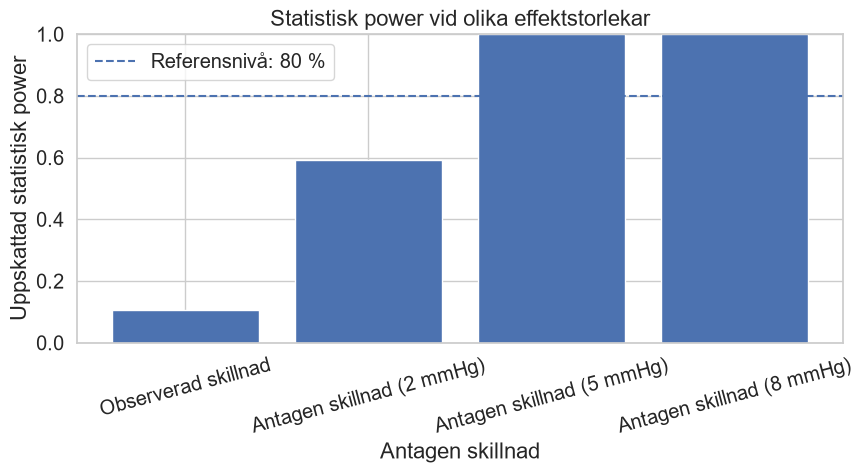

In [95]:

plt.figure(figsize=(9, 5))

plt.bar(
    power_result.keys(),
    power_result.values()
)

# Referenslinje för 80 % power
plt.axhline(
    y=0.80,
    linestyle="--",
    label="Referensnivå: 80 %"
)

plt.ylim(0, 1)
plt.ylabel("Uppskattad statistisk power")
plt.xlabel("Antagen skillnad")
plt.title("Statistisk power vid olika effektstorlekar")

plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


Tolkning – poweranalys
Den simulerade powern är cirka 10,6 % vid den observerade skillnaden 0,47 mmHg, 59,2 % vid antagen skillnad 2 mmHg och 99,9 % vid 5 mmHg. Detta visar att testets möjlighet att upptäcka en skillnad beror starkt på hur stor den sanna effekten antas vara. Resultaten bygger på simulerade normalfördelade värden och de observerade gruppstorlekarna och standardavvikelserna. De visar inte att effekten faktiskt är 2 eller 5 mmHg.

## Kompletterande analys – sjukdomsandel bland rökare och icke-rökare


In [118]:
from statsmodels.stats.proportion import (
    proportions_ztest, 
    proportion_confint, 
    confint_proportions_2indep,
    proportion_effectsize
)

from statsmodels.stats.power import NormalIndPower
from pathlib import Path

## 1. Beskrivande statistik – Sjukdomsandel

Syftet är att undersöka om sjukdomsandelen skiljer sig mellan
rökare och icke-rökare.

- Oberoende variabel: smoker (Yes/No)
- Beroende variabel: disease (0/1)

Här beräknar antal observationer, antal sjukdomsfall och
sjukdomsandel för respektive grupp.

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from statsmodels.stats.proportion import (
    proportion_confint,
    proportions_ztest,
    confint_proportions_2indep,
    proportion_effectsize
)
from statsmodels.stats.power import NormalIndPower


In [121]:
# Inställningar
alpha = 0.05
np.random.seed(42)

# Funktion för procentformatering
def pct(x):
    return f"{x * 100:.1f}%"

# Sammanfatta sjukdomsandel per grupp
summary = (
    df.groupby("smoker")["disease"]
    .agg(
        observations="count",
        disease_cases="sum",
        disease_proportion="mean"
    )
    .reset_index()
)

summary

,smoker,observations,disease_cases,disease_proportion
0,No,587,28,0.047700
1,Yes,213,19,0.089202


## 2. Konfidensintervall och hypotesprövning

Fråga: Skiljer sig andelen med sjukdom mellan rökare och icke-rökare? Detta är en separat explorativ analys.
- H₀: Andelen med sjukdom är lika i båda grupperna.
- H₁: Andelarna skiljer sig (tvåsidigt).

Metoder:
- Wilsons 95 % konfidensintervall för varje grupp
- Ensidigt z-test för två proportioner
- 95 % konfidensintervall för skillnaden (Newcombe)
- Absolut och relativ skillnad

In [122]:
#Confidence intervals and hypothesis test

A = summary.loc[summary["smoker"] == "No"].iloc[0]
B = summary.loc[summary["smoker"] == "Yes"].iloc[0]

n_A = int(A["observations"])
n_B = int(B["observations"])

x_A = int(A["disease_cases"])
x_B = int(B["disease_cases"])

p_A = x_A / n_A
p_B = x_B / n_B

# Skillnad i sjukdomsandel
diff = p_B - p_A

# Absolut lift i procentenheter
absolute_pp = diff * 100

# Relativ lift i procent
relative_lift = (
    (p_B / p_A - 1) * 100
    if p_A > 0 else np.nan
)

# 95 % KI för varje grupp
ci_A = proportion_confint(x_A, n_A, method="wilson")
ci_B = proportion_confint(x_B, n_B, method="wilson")

# 95 % KI för skillnaden mellan grupperna
diff_ci_low, diff_ci_high = confint_proportions_2indep(
    count1=x_B,
    nobs1=n_B,
    count2=x_A,
    nobs2=n_A,
    alpha=alpha,
    compare="diff",
    method="newcomb"
)

# Ensidigt z-test: Rökare > Icke-rökare
z_stat, p_one_sided = proportions_ztest(
    count=[x_B, x_A],
    nobs=[n_B, n_A],
    alternative="larger"
)

# Tvåsidigt z-test
_, p_two_sided = proportions_ztest(
    count=[x_B, x_A],
    nobs=[n_B, n_A],
    alternative="two-sided"
)

# Sammanfattning
conclusion = f"""
------------ SJUKDOMSANDEL ------------

Icke-rökare (A):
Antal: {n_A}
Sjukdomsfall: {x_A}
Andel: {pct(p_A)}
95 % KI: [{pct(ci_A[0])}, {pct(ci_A[1])}]

Rökare (B):
Antal: {n_B}
Sjukdomsfall: {x_B}
Andel: {pct(p_B)}
95 % KI: [{pct(ci_B[0])}, {pct(ci_B[1])}]

------------ JÄMFÖRELSE ------------

Absolut lift (B - A): {absolute_pp:.2f} procentenheter
Relativ lift: {relative_lift:.1f} %

95 % KI för skillnaden:
[{diff_ci_low*100:.2f}, {diff_ci_high*100:.2f}] pp

Z-statistik: {z_stat:.4f}
Tvåsidigt p-värde: {p_two_sided:.4f}
Ensidigt p-värde (B > A): {p_one_sided:.4f}
"""

print(conclusion)

if p_one_sided < alpha:
    print("Beslut: Förkasta H0.")
    print("Rökare har statistiskt signifikant högre sjukdomsandel.")
else:
    print("Beslut: Kan inte förkasta H0.")
    print("Otillräckligt stöd för högre sjukdomsandel bland rökare.")


------------ SJUKDOMSANDEL ------------

Icke-rökare (A):
Antal: 587
Sjukdomsfall: 28
Andel: 4.8%
95 % KI: [3.3%, 6.8%]

Rökare (B):
Antal: 213
Sjukdomsfall: 19
Andel: 8.9%
95 % KI: [5.8%, 13.5%]

------------ JÄMFÖRELSE ------------

Absolut lift (B - A): 4.15 procentenheter
Relativ lift: 87.0 %

95 % KI för skillnaden:
[0.41, 8.96] pp

Z-statistik: 2.2063
Tvåsidigt p-värde: 0.0274
Ensidigt p-värde (B > A): 0.0137

Beslut: Förkasta H0.
Rökare har statistiskt signifikant högre sjukdomsandel.


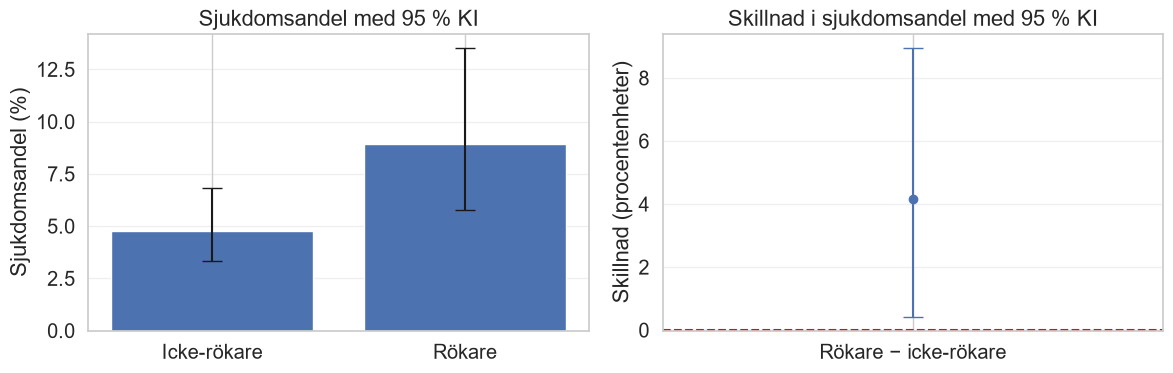

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Diagram 1: Sjukdomsandel per grupp

proportions = np.array([p_A, p_B]) * 100
errors = [
    [(p_A - ci_A[0])*100, (p_B - ci_B[0])*100],
    [(ci_A[1] - p_A)*100, (ci_B[1] - p_B)*100]
]

axes[0].bar(
    ["Icke-rökare", "Rökare"],
    proportions,
    yerr=errors,
    capsize=7
)

axes[0].set_ylabel("Sjukdomsandel (%)")
axes[0].set_title("Sjukdomsandel med 95 % KI")
axes[0].grid(axis="y", alpha=0.3)

# Diagram 2: Skillnad mellan grupper
axes[1].errorbar(
    [0],
    [diff * 100],
    yerr=[
        [(diff - diff_ci_low) * 100],
        [(diff_ci_high - diff) * 100]
    ],
    fmt="o",
    capsize=7
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xticks([0])
axes[1].set_xticklabels(["Rökare − icke-rökare"])
axes[1].set_ylabel("Skillnad (procentenheter)")
axes[1].set_title("Skillnad i sjukdomsandel med 95 % KI")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Power Analysis

In [147]:

# Effektstorlek för två proportioner
effect_size = proportion_effectsize(p_B, p_A)

# Skapa power-modell
power_model = NormalIndPower()

# Beräkna power med befintliga gruppstorlekar
power = power_model.power(
    effect_size=effect_size,
    nobs1=n_B,
    alpha=0.05,
    ratio=n_A / n_B,
    alternative="larger"
)

power_summary = f"""

Effektstorlek (Cohen's h): {effect_size:.3f}
Signifikansnivå: {alpha}
Analytisk power: {pct(power)}
"""

print(power_summary)



Effektstorlek (Cohen's h): 0.166
Signifikansnivå: 0.05
Analytisk power: 66.8%



## 4. Simulerad statistisk power

Här använder binomialfördelningen eftersom disease är
en binär variabel (0 eller 1).

Vi simulerar 5 000 nya studier med samma gruppstorlekar
och antagna sjukdomsandelar.

För varje simulering utförs ett ensidigt z-test.

Andelen signifikanta tester används som uppskattad power..


In [135]:

def simulated_power(
    p_smokers,
    p_non_smokers,
    n_smokers,
    n_non_smokers,
    n_simulations=5000,
    alpha=0.05,
    seed=42
):
    """
    Simulerar power för ett ensidigt z-test
    av två sjukdomsandelar.
    """
    rng = np.random.default_rng(seed)
    significant = 0

    for _ in range(n_simulations):

        # Simulera antal sjuka i varje grupp
        x_smokers = np.random.binomial(n_smokers, p_smokers)
        x_non_smokers = np.random.binomial(n_non_smokers, p_non_smokers)

        # Ensidigt z-test
        _, p_value = proportions_ztest(
            count=[x_smokers, x_non_smokers],
            nobs=[n_smokers, n_non_smokers],
            alternative="larger"
        )

        # Räkna signifikanta resultat
        if np.isfinite(p_value) and p_value < alpha:
            significant += 1

    return significant / n_simulations


sim_power = simulated_power(
    p_smokers=p_B,
    p_non_smokers=p_A,
    n_smokers=n_B,
    n_non_smokers=n_A
)

simulation_summary = f"""
------------ POWERJÄMFÖRELSE ------------

Antal simuleringar: 5000
Signifikansnivå: {alpha}

Analytisk power: {pct(power)}
Simulerad power: {pct(sim_power)}
Skillnad mellan metoderna: {abs(sim_power-power)*100:.2f} pp
"""

print(simulation_summary)


------------ POWERJÄMFÖRELSE ------------

Antal simuleringar: 5000
Signifikansnivå: 0.05

Analytisk power: 66.8%
Simulerad power: 69.3%
Skillnad mellan metoderna: 2.58 pp



## 5. Power vid olika antagna sjukdomsandelar

Här undersöker hur statistisk power förändras när
den antagna sjukdomsandelen bland rökare ökar.

Sjukdomsandelen bland icke-rökare hålls konstant.

Vi jämför:
- Ingen skillnad
- Liten skillnad
- Observerad skillnad
- Större skillnader

Syftet är att undersöka hur effektstorleken
påverkar sannolikheten att upptäcka en skillnad.

In [144]:
# Antagna sjukdomsandelar bland rökare
assumed_proportions = [p_A, 0.06, p_B, 0.12, 0.15]

power_results = []

for assumed_p in assumed_proportions:

    result = simulated_power(
        p_smokers=assumed_p,
        p_non_smokers=p_A,
        n_smokers=n_B,
        n_non_smokers=n_A
    )
    power_results.append(result)

  
    print(
        f"Rökare: {assumed_p:.1%} | "
        f"Skillnad: {(assumed_p-p_A)*100:.2f} pp | "
        f"Power: {result:.1%}"
    )


Rökare: 4.8% | Skillnad: 0.00 pp | Power: 4.9%
Rökare: 6.0% | Skillnad: 1.23 pp | Power: 17.6%
Rökare: 8.9% | Skillnad: 4.15 pp | Power: 69.0%
Rökare: 12.0% | Skillnad: 7.23 pp | Power: 95.6%
Rökare: 15.0% | Skillnad: 10.23 pp | Power: 99.8%


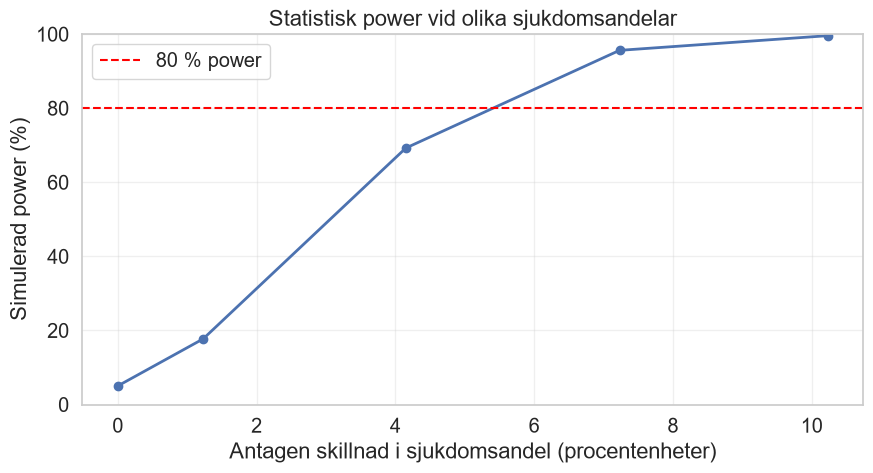

In [116]:
import matplotlib.pyplot as plt

differences = [
    (p - p_A) * 100
    for p in assumed_proportions
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    differences,
    np.array(power_results) * 100,
    marker="o",
    linewidth=2
)

ax.axhline(
    80,
    color="red",
    linestyle="--",
    label="80 % power"
)

ax.set_xlabel("Antagen skillnad i sjukdomsandel (procentenheter)")
ax.set_ylabel("Simulerad power (%)")
ax.set_title("Statistisk power vid olika sjukdomsandelar")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [146]:
final_summary = f"""
========== HÄLSOSTUDIE: SLUTRESULTAT ==========

1. SJUKDOMSANDEL

Icke-rökare: {pct(p_A)}
Rökare: {pct(p_B)}

2. EFFEKT

Absolut lift: {absolute_pp:.2f} procentenheter
Relativ lift: {relative_lift:.1f} %
95 % KI: [{diff_ci_low*100:.2f}, {diff_ci_high*100:.2f}] pp

3. HYPOTESPRÖVNING

Ensidigt p-värde: {p_one_sided:.4f}
Tvåsidigt p-värde: {p_two_sided:.4f}
Signifikansnivå: {alpha}

4. POWER

Cohen's h: {effect_size:.3f}
Analytisk power: {pct(power)}
Simulerad power: {pct(sim_power)}

5. SLUTSATS

{"Statistiskt signifikant högre sjukdomsandel bland rökare."
 if p_one_sided < alpha
 else "Ingen statistiskt säkerställd högre sjukdomsandel bland rökare."}

Poweranalysen visar hur känslig studien är för
olika antagna skillnader i sjukdomsandel.

================================================
"""

print(final_summary)


========== HÄLSOSTUDIE: SLUTRESULTAT ==========

1. SJUKDOMSANDEL

Icke-rökare: 4.8%
Rökare: 8.9%

2. EFFEKT

Absolut lift: 4.15 procentenheter
Relativ lift: 87.0 %
95 % KI: [0.41, 8.96] pp

3. HYPOTESPRÖVNING

Ensidigt p-värde: 0.0137
Tvåsidigt p-värde: 0.0274
Signifikansnivå: 0.05

4. POWER

Cohen's h: 0.166
Analytisk power: 66.8%
Simulerad power: 69.3%

5. SLUTSATS

Statistiskt signifikant högre sjukdomsandel bland rökare.

Poweranalysen visar hur känslig studien är för
olika antagna skillnader i sjukdomsandel.


